In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA

print("Libraries imported successfully")

Libraries imported successfully


In [3]:

df = pd.read_csv('/content/Cleaned_Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (46650, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:

numeric_features = [
    'Days for shipment (scheduled)',
        'Benefit per order',
            'Sales per customer',
                'Order Item Discount',
                    'Order Item Discount Rate',
                        'Order Item Product Price',
                            'Order Item Quantity',
                                'Sales',
                                    'Order Item Total',
                                        'Order Item Profit Ratio',
                                            'Product Price'
                                            ]

categorical_features = [
                                                'Type',
                                                    'Category Name',
                                                        'Customer Segment',
                                                            'Department Name',
                                                                'Market',
                                                                    'Order Region',
                                                                        'Shipping Mode'
                                                                        ]

X = df[numeric_features + categorical_features].copy()
y = df['Late_delivery_risk'].copy()

print("Input shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Input shape: (46650, 18)

Target distribution:
Late_delivery_risk
1    27306
0    19344
Name: count, dtype: int64


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
        test_size=0.20,
            random_state=42,
                stratify=y
                )

numeric_pipeline = Pipeline([
                    ('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())
                        ])

categorical_pipeline = Pipeline([
                            ('imputer', SimpleImputer(strategy='most_frequent')),
                                ('encoder', OneHotEncoder(
                                        handle_unknown='ignore',
                                                sparse_output=False
                                                    ))
                                                    ])

preprocessor = ColumnTransformer([
                                                        ('numeric', numeric_pipeline, numeric_features),
                                                            ('categorical', categorical_pipeline, categorical_features)
                                                            ])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (37320, 103)
Testing data after preprocessing: (9330, 103)


In [6]:

selector = SelectKBest(
    score_func=mutual_info_classif,
        k=10
        )

X_train_selected = selector.fit_transform(
            X_train_processed, y_train
            )

X_test_selected = selector.transform(X_test_processed)

feature_names = preprocessor.get_feature_names_out()
selected_mask = selector.get_support()

selected_features = feature_names[selected_mask]
selected_scores = selector.scores_[selected_mask]

results = pd.DataFrame({
                'Feature': selected_features,
                    'Mutual Information Score': selected_scores
                    }).sort_values(
                        'Mutual Information Score',
                            ascending=False
                            )

display(results)

print("Features before selection:", X_train_processed.shape[1])
print("Features after selection:", X_train_selected.shape[1])

,Feature,Mutual Information Score
0,numeric__Days for shipment (scheduled),0.162730
7,categorical__Shipping Mode_First Class,0.117068
9,categorical__Shipping Mode_Standard Class,0.114666
8,categorical__Shipping Mode_Second Class,0.016925
1,categorical__Type_TRANSFER,0.009793
3,categorical__Customer Segment_Consumer,0.006145
4,categorical__Customer Segment_Corporate,0.005220
2,categorical__Category Name_Electronics,0.004412
5,categorical__Department Name_Apparel,0.004344
6,categorical__Order Region_Southern Europe,0.004223


Features before selection: 103
Features after selection: 10


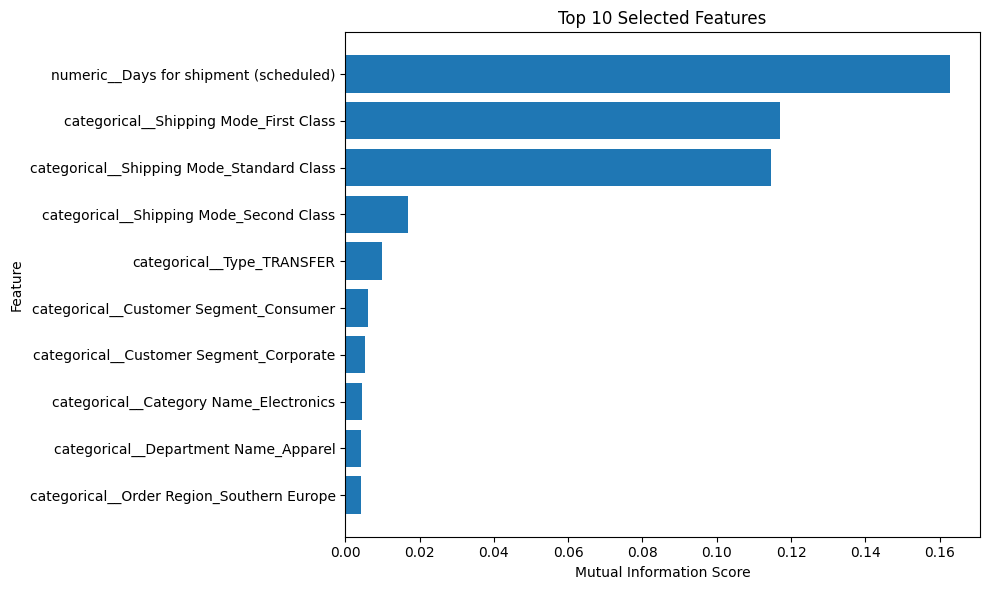

In [8]:

plot_data = results.sort_values(
    'Mutual Information Score'
    )

plt.figure(figsize=(10, 6))

plt.barh(
        plot_data['Feature'],
            plot_data['Mutual Information Score']
            )

plt.xlabel('Mutual Information Score')
plt.ylabel('Feature')
plt.title('Top 10 Selected Features')

plt.tight_layout()
plt.show()

In [9]:

pca = PCA(
    n_components=0.95,
        svd_solver='full'
        )

X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

print("Features before PCA:", X_train_processed.shape[1])
print("Components after PCA:", X_train_pca.shape[1])

print(
            "Variance retained:",
round(pca.explained_variance_ratio_.sum() * 100, 2),
                    "%"
                    )

Features before PCA: 103
Components after PCA: 26
Variance retained: 95.01 %


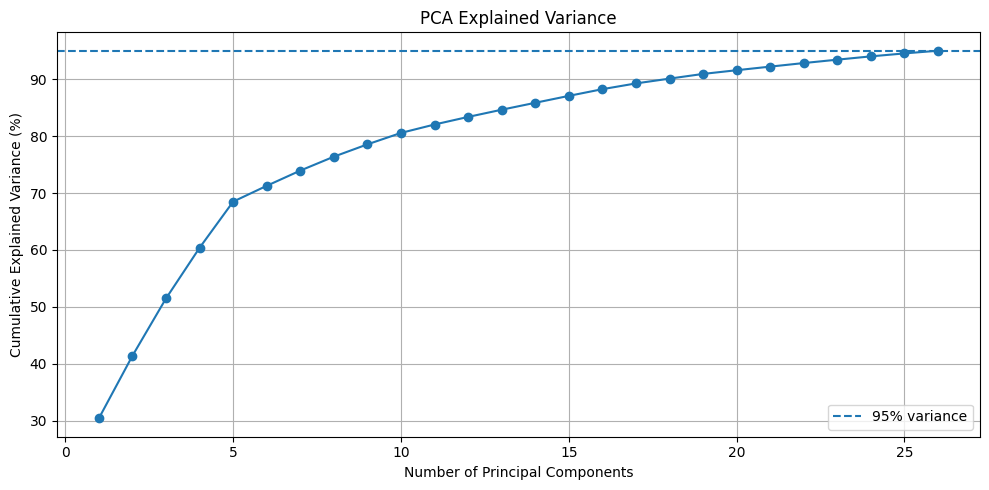

In [10]:

individual_variance = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(individual_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
        cumulative_variance,
            marker='o'
            )

plt.axhline(
                y=95,
                    linestyle='--',
                        label='95% variance'
                        )

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA Explained Variance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

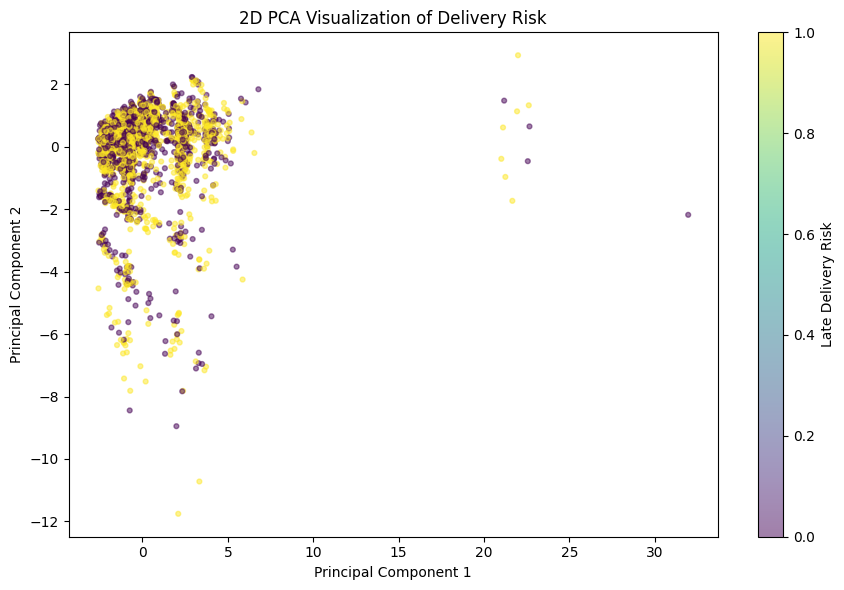

Variance explained by two components: 41.4 %


In [12]:

pca_2d = PCA(n_components=2)

X_train_2d = pca_2d.fit_transform(X_train_processed)

sample_size = min(3000, len(X_train_2d))
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(X_train_2d),
        size=sample_size,
            replace=False
            )

plt.figure(figsize=(9, 6))

plt.scatter(
                X_train_2d[sample_indices, 0],
                    X_train_2d[sample_indices, 1],
                        c=y_train.iloc[sample_indices],
                            alpha=0.5,
                                s=12
                                )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D PCA Visualization of Delivery Risk')
plt.colorbar(label='Late Delivery Risk')

plt.tight_layout()
plt.show()

print(
                                    "Variance explained by two components:",
round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
                                            "%"
                                            )